# 03 · Solution 1: Mutual Information (filter) + SVM (RBF kernel)

### Feature selection: Mutual Information (MI)
MI measures how much knowing a feature reduces our uncertainty about the emotion label:

$$I(X;Y) = \sum_{x,y} p(x,y)\,\log\frac{p(x,y)}{p(x)\,p(y)}$$

It is 0 when the feature tells us nothing about the emotion and grows as the feature becomes more informative. Unlike correlation, it also catches **non-linear** relationships. For continuous features, scikit-learn estimates MI with a k-nearest-neighbour method (Kraskov et al., 2004; Ross, 2014).

MI is a **filter** method: it ranks every feature on its own, *before* and independently of the classifier. That makes it fast. Its weakness is that two highly correlated features both get high scores, so redundancy is not removed.

### Classifier: Support Vector Machine with RBF kernel
The SVM finds the boundary with the widest margin between classes. The RBF kernel $K(\mathbf{x},\mathbf{x}') = \exp(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^2)$ lets that boundary be curved. Eight classes are handled with one-vs-one voting. `class_weight="balanced"` makes up for neutral having half as many clips.

### What is tuned (inside the training actors only)
- **k**, the number of top-MI features kept: 10 … 190
- **C** (margin softness): 0.3, 1, 3, 10, 30
- **γ** = m / k with m ∈ {0.25, 0.5, 1, 2} (scales the kernel width with the number of features)

**How k is chosen (one-standard-error rule).** For every k, the inner loop records the best macro-F1 over all settings. We then pick the *smallest* k whose score is within one standard error of the overall best (Hastie, Tibshirani & Friedman, *Elements of Statistical Learning*, §7.10). When several subset sizes perform about the same, this prefers the smaller, simpler one, the same idea as the size penalty in the GA. The standard error comes from only 3 inner folds, so it is a rough estimate. We first ran the plain "best inner score" rule. Its results are kept in `results/argmax_rule/` and compared in notebook 06, so the choice of rule is fully transparent.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ser.config import EMOTION_ORDER, FEATURES_CSV, RANDOM_STATE
from ser.evaluation import actor_folds, nested_ranked_cv, rank_all, rank_mutual_info, scores
from ser.features import feature_group
from ser.models import K_GRID, SVM_GRID, make_svm
from ser.plots import (GREY, SOLUTION_COLORS, plot_confusion, plot_k_curve,
                       plot_selection_frequency, save, set_style)

set_style()
COLOR = SOLUTION_COLORS["S1: MI + SVM"]

In [2]:
df = pd.read_csv(FEATURES_CSV)
META = ["file", "actor", "gender", "emotion_id", "emotion", "intensity", "statement", "repetition"]
FEATURES = [c for c in df.columns if c not in META]
X, y, actors = df[FEATURES].to_numpy(), df["emotion"].to_numpy(), df["actor"].to_numpy()
print(f"X: {X.shape}, classes: {len(set(y))}")

pd.DataFrame({"fold": range(1, 7), "test actors (unseen)": [str(f) for f in actor_folds()]})

X: (1440, 190), classes: 8


,fold,test actors (unseen)
0,1,"[1, 12, 15, 24]"
1,2,"[6, 10, 13, 19]"
2,3,"[7, 16, 20, 23]"
3,4,"[4, 5, 11, 18]"
4,5,"[9, 14, 21, 22]"
5,6,"[2, 3, 8, 17]"


## 1. Baseline: SVM on all 190 features (no selection)
Same protocol and same tuning of C and γ, but every feature is used. Comparing with this tells us what feature selection itself adds.

In [3]:
base = nested_ranked_cv("Baseline SVM: all features", X, y, actors, FEATURES, rank_all, make_svm,
                        SVM_GRID, k_grid=[len(FEATURES)], files=df.file)
base.save()
base.summary().round(3)

[Baseline SVM: all features] fold 1/6 actors [np.int64(1), np.int64(12), np.int64(15), np.int64(24)]: acc=0.621 F1=0.618 k=190 {'C': 1.0, 'gamma_mult': 0.5} (13s)


[Baseline SVM: all features] fold 2/6 actors [np.int64(6), np.int64(10), np.int64(13), np.int64(19)]: acc=0.479 F1=0.481 k=190 {'C': 3.0, 'gamma_mult': 1.0} (6s)


[Baseline SVM: all features] fold 3/6 actors [np.int64(7), np.int64(16), np.int64(20), np.int64(23)]: acc=0.608 F1=0.578 k=190 {'C': 3.0, 'gamma_mult': 0.5} (5s)


[Baseline SVM: all features] fold 4/6 actors [np.int64(4), np.int64(5), np.int64(11), np.int64(18)]: acc=0.504 F1=0.454 k=190 {'C': 1.0, 'gamma_mult': 1.0} (6s)


[Baseline SVM: all features] fold 5/6 actors [np.int64(9), np.int64(14), np.int64(21), np.int64(22)]: acc=0.529 F1=0.532 k=190 {'C': 3.0, 'gamma_mult': 0.5} (6s)


[Baseline SVM: all features] fold 6/6 actors [np.int64(2), np.int64(3), np.int64(8), np.int64(17)]: acc=0.675 F1=0.665 k=190 {'C': 1.0, 'gamma_mult': 1.0} (5s)


,accuracy,macro_f1,uar,n_features,fit_seconds
mean,0.569,0.554,0.562,190.0,0.212
std,0.077,0.081,0.082,0.0,0.107


## 2. Solution 1: MI ranking + SVM
In every outer fold, MI is computed on the 20 training actors only. The inner loop picks k (one-standard-error rule) together with C and γ, and the model is then tested once on the 4 held-out actors.

In [4]:
s1 = nested_ranked_cv("S1: MI + SVM", X, y, actors, FEATURES, rank_mutual_info, make_svm,
                      SVM_GRID, k_grid=K_GRID, files=df.file)
s1.save()
s1.summary().round(3)

[S1: MI + SVM] fold 1/6 actors [np.int64(1), np.int64(12), np.int64(15), np.int64(24)]: acc=0.554 F1=0.536 k=60 {'C': 10.0, 'gamma_mult': 0.25} (42s)


[S1: MI + SVM] fold 2/6 actors [np.int64(6), np.int64(10), np.int64(13), np.int64(19)]: acc=0.492 F1=0.493 k=120 {'C': 3.0, 'gamma_mult': 0.5} (54s)


[S1: MI + SVM] fold 3/6 actors [np.int64(7), np.int64(16), np.int64(20), np.int64(23)]: acc=0.567 F1=0.528 k=120 {'C': 1.0, 'gamma_mult': 0.5} (53s)


[S1: MI + SVM] fold 4/6 actors [np.int64(4), np.int64(5), np.int64(11), np.int64(18)]: acc=0.500 F1=0.480 k=80 {'C': 3.0, 'gamma_mult': 0.5} (58s)


[S1: MI + SVM] fold 5/6 actors [np.int64(9), np.int64(14), np.int64(21), np.int64(22)]: acc=0.479 F1=0.467 k=80 {'C': 3.0, 'gamma_mult': 1.0} (43s)


[S1: MI + SVM] fold 6/6 actors [np.int64(2), np.int64(3), np.int64(8), np.int64(17)]: acc=0.637 F1=0.629 k=150 {'C': 10.0, 'gamma_mult': 1.0} (45s)


,accuracy,macro_f1,uar,n_features,fit_seconds
mean,0.538,0.522,0.531,101.667,0.116
std,0.060,0.059,0.054,33.714,0.071


In [5]:
s1.folds[["fold", "test_actors", "accuracy", "macro_f1", "uar", "n_features", "params"]].round(3)

,fold,test_actors,accuracy,macro_f1,uar,n_features,params
0,0,1 12 15 24,0.554,0.536,0.531,60,"{""C"": 10.0, ""gamma_mult"": 0.25}"
1,1,6 10 13 19,0.492,0.493,0.496,120,"{""C"": 3.0, ""gamma_mult"": 0.5}"
2,2,7 16 20 23,0.567,0.528,0.547,120,"{""C"": 1.0, ""gamma_mult"": 0.5}"
3,3,4 5 11 18,0.500,0.480,0.492,80,"{""C"": 3.0, ""gamma_mult"": 0.5}"
4,4,9 14 21 22,0.479,0.467,0.488,80,"{""C"": 3.0, ""gamma_mult"": 1.0}"
5,5,2 3 8 17,0.638,0.629,0.629,150,"{""C"": 10.0, ""gamma_mult"": 1.0}"


## 3. How many features do we need?
The solid line is the macro-F1 on the unseen test actors for every k (using each fold's chosen C and γ). The dashed line is what the inner validation saw when it picked k. The dotted grey line is the all-features baseline.

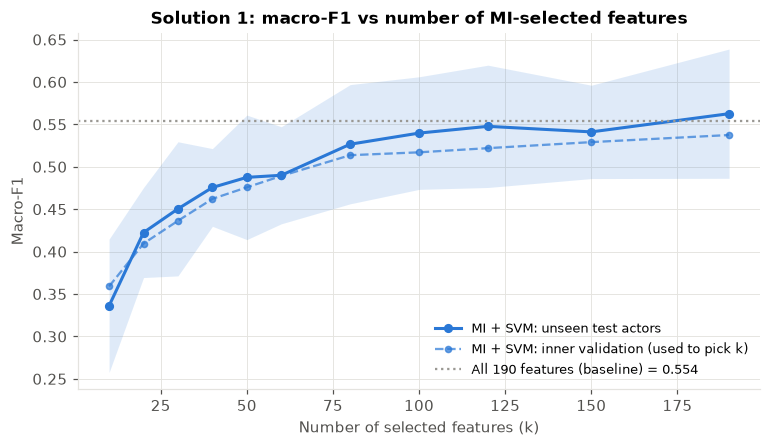

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_k_curve(s1.inner_curve, s1.outer_curve, COLOR, "MI + SVM",
             baseline=base.folds.macro_f1.mean(), ax=ax)
ax.set_title("Solution 1: macro-F1 vs number of MI-selected features")
save(fig, "08a_s1_k_curve")
plt.show()

## 4. Confusion matrix (all 1,440 out-of-fold predictions)
Each clip is predicted exactly once, by the model that did not see its actor. Rows sum to 100 %.

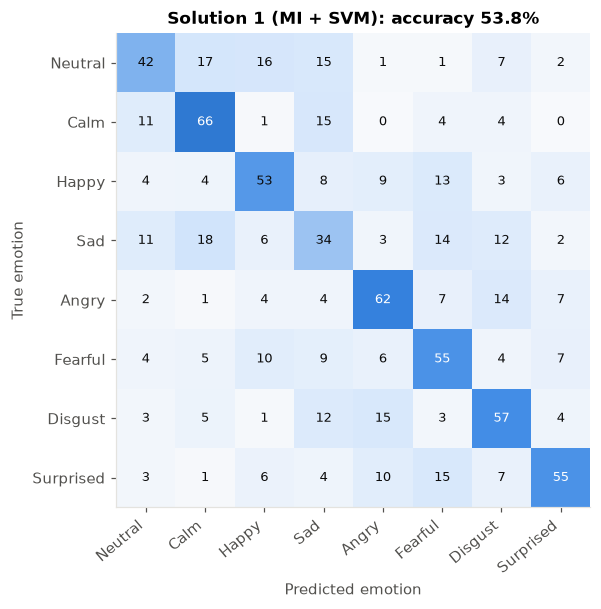

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
plot_confusion(s1.oof.y_true, s1.oof.y_pred, EMOTION_ORDER,
               f"Solution 1 (MI + SVM): accuracy {scores(s1.oof.y_true, s1.oof.y_pred)['accuracy']:.1%}", ax=ax)
save(fig, "10a_s1_confusion")
plt.show()

## 5. Which features did MI choose?
Left: how consistently each feature was picked across the six outer folds (stability). Right: which feature families make up the selected sets.

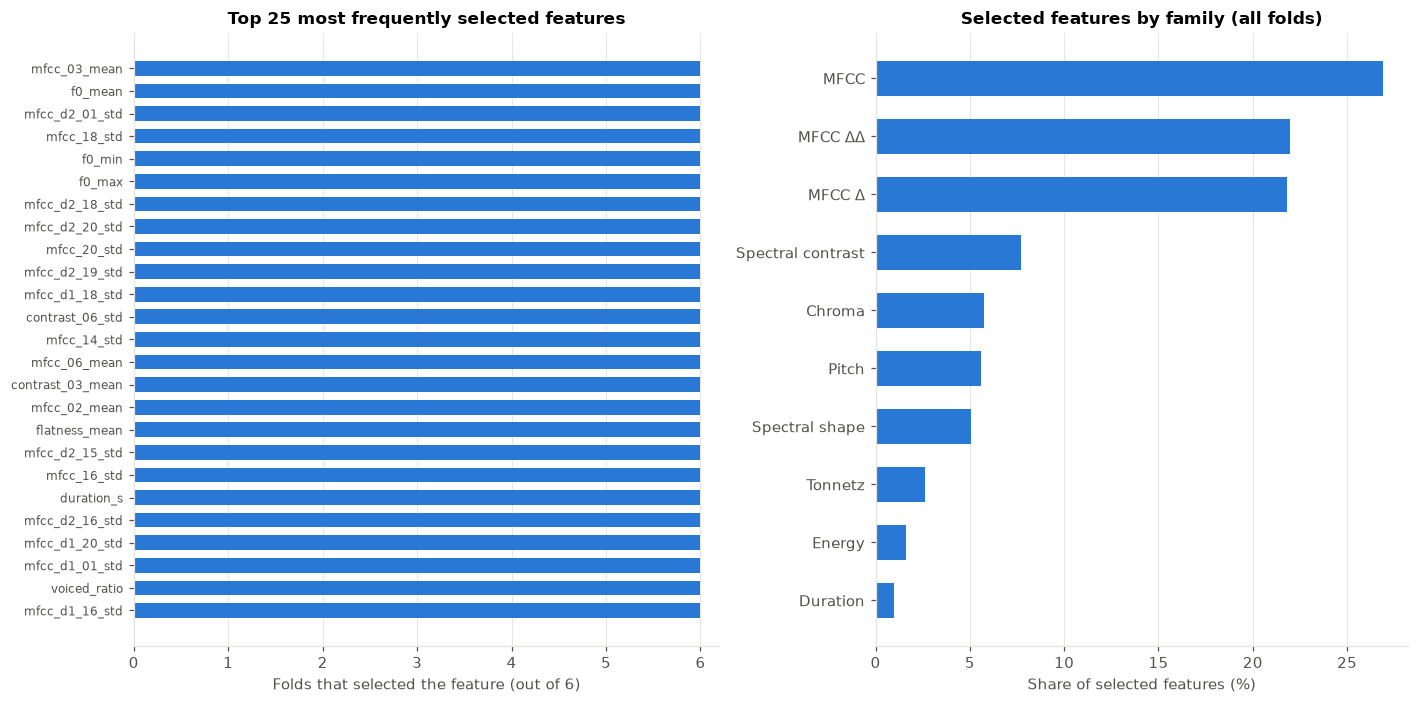

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
plot_selection_frequency(s1.selected, top=25, color=COLOR, title="Top 25 most frequently selected features", ax=axes[0])
fam = pd.Series([feature_group(f) for fold in s1.selected for f in fold]).value_counts(normalize=True) * 100
axes[1].barh(fam.index[::-1], fam.values[::-1], color=COLOR, height=0.6)
axes[1].set_xlabel("Share of selected features (%)")
axes[1].set_title("Selected features by family (all folds)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "11a_s1_selected_features")
plt.show()

For interpretation only, these are the MI scores computed on all 1,440 clips. They are **not** used for any model, because that would leak test information.

In [9]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
mi_all = pd.Series(mutual_info_classif(StandardScaler().fit_transform(X), y, n_neighbors=3,
                                       random_state=RANDOM_STATE), index=FEATURES).sort_values(ascending=False)
mi_all.head(15).round(3).to_frame("mutual information (nats)")

,mutual information (nats)
mfcc_d2_01_std,0.188
f0_mean,0.179
mfcc_03_mean,0.171
mfcc_18_std,0.163
f0_max,0.158
f0_min,0.156
mfcc_20_std,0.142
mfcc_d2_20_std,0.140
mfcc_d2_18_std,0.134
contrast_06_std,0.133


## 6. Summary

In [10]:
summary = pd.concat({"Baseline SVM (all 190)": base.summary(), "S1: MI + SVM": s1.summary()})
summary.round(3)

accuracy  macro_f1    uar  n_features  \
Baseline SVM (all 190) mean     0.569     0.554  0.562     190.000   
                       std      0.077     0.081  0.082       0.000   
S1: MI + SVM           mean     0.538     0.522  0.531     101.667   
                       std      0.060     0.059  0.054      33.714   

                             fit_seconds  
Baseline SVM (all 190) mean        0.212  
                       std         0.107  
S1: MI + SVM           mean        0.116  
                       std         0.071

In [11]:
d = s1.folds.macro_f1.mean() - base.folds.macro_f1.mean()
print(f"Macro-F1 change from feature selection: {d:+.3f}")
print(f"Features used: {base.folds.n_features.mean():.0f} -> {s1.folds.n_features.mean():.0f} on average "
      f"({100 * (1 - s1.folds.n_features.mean() / base.folds.n_features.mean()):.0f}% fewer)")

Macro-F1 change from feature selection: -0.032
Features used: 190 -> 102 on average (46% fewer)
